# Group XX - Machine Learning, Element 1: Apply dataset preparation mechanisms
| Item | Details |
|---|---|
| Group | **Group XX** |
| Members | **IGIHOZO Bienvenue** and **MUGISHA Aime Patrick** |
| Question | **Q1 - Predicting maize yield for farmer cooperatives in Rwanda (MCSU)** |
| Stage | **5 - Engineer and select features (+ Stage 6 final files)** |
| Driver / Navigator | Driver: IGIHOZO Bienvenue / Navigator: MUGISHA Aime Patrick |


## Stage 5 - Engineer and select features (PC 1.4)
New features use only values of the same row, so they cannot leak between splits. Every statistic used for **selection** is
computed on the **training set only**.

In [1]:
import sys  # lets us tell Python where our own code (src/) is
from pathlib import Path  # file paths that work on every computer
import warnings  # hide harmless library notices
warnings.filterwarnings("ignore")  # keep the output readable
import numpy as np  # maths on whole columns
import pandas as pd  # the DataFrame table
ROOT = Path.cwd().parent  # notebooks/ is inside q1_maize_yield
sys.path.insert(0, str(ROOT / "src"))  # make src/maize_pipeline.py importable
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)  # show every column
RAW = ROOT / "data" / "raw" / "maize_yield_rwanda_rw.csv"  # the original file (never edited)
import maize_pipeline as mp  # our reusable functions

import matplotlib.pyplot as plt  # charts
import seaborn as sns  # charts
INTERIM, PROCESSED, FIG = ROOT / "data" / "interim", ROOT / "data" / "processed", ROOT / "docs" / "figures"  # folders
PROCESSED.mkdir(parents=True, exist_ok=True)  # create if needed
splits = {n: mp.add_features(pd.read_csv(INTERIM / f"{n}_clean.csv")) for n in ["train", "val", "test"]}  # SAME steps on each split
train = splits["train"]  # shortcut
new_cols = ["n_applied_kg_ha", "uses_mineral_fertiliser", "seed_class", "improved_package", "log_farm_area_ha",
            "temp_dev_from_optimum", "ph_in_optimal_range", "is_irrigated", "altitude_zone", "plant_density_k_ha"]  # 10 new features
print({n: d.shape for n, d in splits.items()})  # sizes
train[["record_id", "npk_kg_ha", "urea_kg_ha", "seed_variety", "farming_practice", "farm_area_ha"] + new_cols].head()  # first rows

{'train': (998, 33), 'val': (214, 33), 'test': (214, 33)}


,record_id,npk_kg_ha,urea_kg_ha,seed_variety,farming_practice,farm_area_ha,n_applied_kg_ha,uses_mineral_fertiliser,seed_class,improved_package,log_farm_area_ha,temp_dev_from_optimum,ph_in_optimal_range,is_irrigated,altitude_zone,plant_density_k_ha
0,RW-MZ-00493,56.7,23.4,Local,Traditional,0.40,20.403,1,Local,0,0.336472,0.0,1.0,0,Lowland,37.337
1,RW-MZ-00955,19.0,10.0,PAN691,Traditional,0.56,7.830,1,Hybrid,0,0.444686,1.6,1.0,0,Highland,34.965
2,RW-MZ-00790,68.0,28.5,RHM104,Improved,1.35,24.670,1,Hybrid,1,0.854415,0.0,1.0,0,Midland,53.696
3,RW-MZ-01219,91.2,14.5,Local,Improved,1.70,22.174,1,Local,0,0.993252,0.0,1.0,0,Midland,48.577
4,RW-MZ-01374,102.9,45.1,Local,Improved,1.47,38.239,1,Local,0,0.904218,0.0,1.0,0,Lowland,51.829


### 5.1 Skewness -> transformation

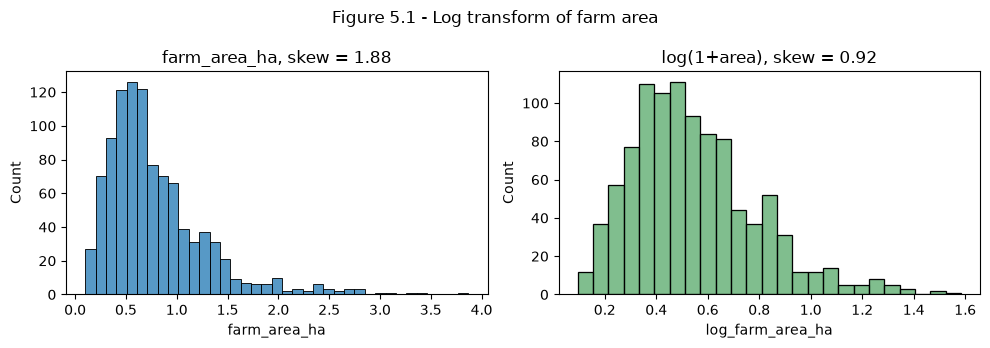

,skewness
farm_area_ha,1.88
log_farm_area_ha,0.92
pest_incidence_index,0.71
manure_t_ha,0.34
yield_t_ha,0.28


In [2]:
sk = train[["farm_area_ha", "log_farm_area_ha", "pest_incidence_index", "manure_t_ha", mp.TARGET]].skew().round(2)  # skewness
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))  # two histograms
sns.histplot(train["farm_area_ha"], ax=axes[0]); axes[0].set_title(f"farm_area_ha, skew = {sk['farm_area_ha']}")  # before
sns.histplot(train["log_farm_area_ha"], ax=axes[1], color="#55A868"); axes[1].set_title(f"log(1+area), skew = {sk['log_farm_area_ha']}")  # after
fig.suptitle("Figure 5.1 - Log transform of farm area"); plt.tight_layout()  # title
plt.savefig(FIG / "fig5_1_log_area.png", dpi=120); plt.show()  # save and display
sk.to_frame("skewness")  # table

**Decision:** farm area is right-skewed; the log version is much closer to symmetric, so we keep the log. The target is not transformed.

### 5.2 Relationship with the target (training set only)

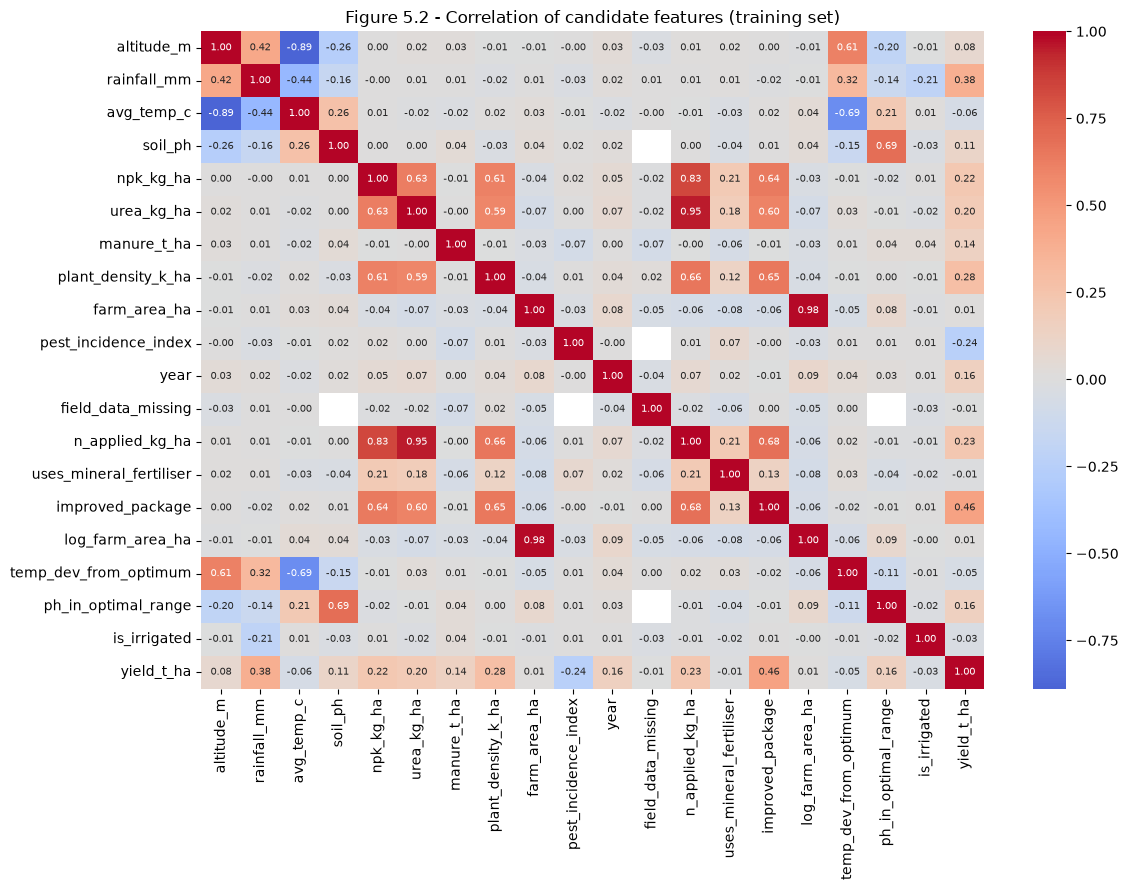

,corr_with_yield
improved_package,0.459
rainfall_mm,0.385
plant_density_k_ha,0.281
pest_incidence_index,-0.244
n_applied_kg_ha,0.229
npk_kg_ha,0.221
urea_kg_ha,0.202
year,0.158
ph_in_optimal_range,0.156
manure_t_ha,0.142


In [3]:
cands = ["altitude_m", "rainfall_mm", "avg_temp_c", "soil_ph", "npk_kg_ha", "urea_kg_ha", "manure_t_ha", "plant_density_k_ha",
         "farm_area_ha", "pest_incidence_index", "year", "field_data_missing", "n_applied_kg_ha", "uses_mineral_fertiliser",
         "improved_package", "log_farm_area_ha", "temp_dev_from_optimum", "ph_in_optimal_range", "is_irrigated"]  # numeric candidates
corr = train[cands + [mp.TARGET]].corr()  # correlation (train)
fig, ax = plt.subplots(figsize=(12, 9))  # chart
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)  # heatmap
ax.set_title("Figure 5.2 - Correlation of candidate features (training set)"); plt.tight_layout()  # title
plt.savefig(FIG / "fig5_2_feature_corr.png", dpi=120); plt.show()  # save and display
corr[mp.TARGET].drop(mp.TARGET).sort_values(key=abs, ascending=False).round(3).to_frame("corr_with_yield")  # ranked

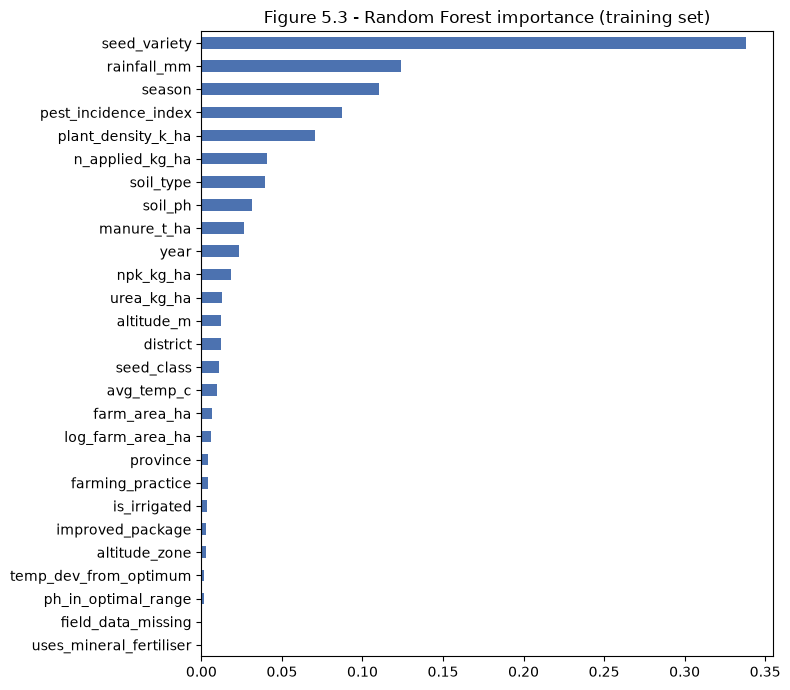

,mutual_info,rf_importance
seed_variety,0.255,0.338
rainfall_mm,0.096,0.124
season,0.139,0.110
pest_incidence_index,0.028,0.087
plant_density_k_ha,0.050,0.070
n_applied_kg_ha,0.061,0.041
soil_type,0.047,0.039
soil_ph,0.021,0.031
manure_t_ha,0.000,0.027
year,0.000,0.023


In [4]:
from sklearn.feature_selection import mutual_info_regression  # any kind of dependence
from sklearn.ensemble import RandomForestRegressor  # quick model for importance
cats = ["season", "province", "district", "soil_type", "seed_variety", "seed_class", "farming_practice", "altitude_zone"]  # categories
X = train[cands].fillna(train[cands].median())  # simple fill with TRAIN medians, only for measuring
X = X.join(train[cats].apply(lambda s: s.astype("category").cat.codes))  # categories as integer codes
mi = pd.Series(mutual_info_regression(X, train[mp.TARGET], random_state=mp.SEED), index=X.columns)  # mutual information
rf = RandomForestRegressor(n_estimators=300, random_state=mp.SEED, n_jobs=-1, min_samples_leaf=3).fit(X, train[mp.TARGET])  # forest
rank = pd.DataFrame({"mutual_info": mi, "rf_importance": rf.feature_importances_}, index=X.columns).sort_values("rf_importance", ascending=False)  # table
fig, ax = plt.subplots(figsize=(8, 7))  # chart
rank["rf_importance"].sort_values().plot.barh(ax=ax, color="#4C72B0")  # bars
ax.set_title("Figure 5.3 - Random Forest importance (training set)"); plt.tight_layout()  # title
plt.savefig(FIG / "fig5_3_rf_importance.png", dpi=120); plt.show()  # save and display
rank.round(3)  # table

### 5.3 Feature selection
1. **Variance threshold** - remove constant / almost constant columns.
2. **Duplicated information** - `province` is fully determined by `district`; pairs with |r| > 0.9 keep the more useful one.
3. **Model-based evidence** - Random Forest importance and mutual information above.

In [5]:
from sklearn.feature_selection import VarianceThreshold  # selection method 1
vt = VarianceThreshold(threshold=0.01).fit(X[cands])  # fit on train
print("near-constant:", [c for c, k in zip(cands, vt.get_support()) if not k] or "none")  # result
up = corr.loc[cands, cands].abs().where(np.triu(np.ones((len(cands),) * 2), k=1).astype(bool))  # upper triangle
print("pairs with |r| > 0.9:\n", up.stack()[lambda s: s > 0.9].round(3).to_string())  # strongly related pairs
print("provinces per district:", train.groupby("district")["province"].nunique().max(), "-> province is redundant")  # 1

near-constant: ['field_data_missing']
pairs with |r| > 0.9:
 urea_kg_ha    n_applied_kg_ha     0.953
farm_area_ha  log_farm_area_ha    0.982
provinces per district: 1 -> province is redundant


In [6]:
DROP = {  # removed -> reason (evidence above)
    "province": "fully determined by district (each district in one province)",
    "urea_kg_ha": f"r = {corr.loc['urea_kg_ha', 'n_applied_kg_ha']:.2f} with n_applied_kg_ha, which contains the urea nitrogen",
    "farm_area_ha": f"r = {corr.loc['farm_area_ha', 'log_farm_area_ha']:.2f} with log_farm_area_ha (less skewed)",
    "plant_density_per_ha": "same values as plant_density_k_ha (only divided by 1,000)",
    "irrigation": "replaced by numeric is_irrigated",
    "field_data_missing": f"near-constant (variance threshold): only {int(train['field_data_missing'].sum())} of {len(train)} training farms",
    "record_id": "identifier, not a feature",
    "yield_kg_ha": "same as the target in another unit (would leak the answer)",
}
FINAL_NUMERIC = ["altitude_m", "rainfall_mm", "temp_dev_from_optimum", "avg_temp_c", "soil_ph", "ph_in_optimal_range",
                 "npk_kg_ha", "n_applied_kg_ha", "manure_t_ha", "uses_mineral_fertiliser", "improved_package",
                 "plant_density_k_ha", "log_farm_area_ha", "pest_incidence_index", "is_irrigated", "year"]  # kept numbers
FINAL_NOMINAL = ["season", "district", "soil_type", "seed_variety", "seed_class", "farming_practice", "altitude_zone"]  # kept categories
print(len(FINAL_NUMERIC) + len(FINAL_NOMINAL), "selected input columns:", FINAL_NUMERIC + FINAL_NOMINAL)  # final list

23 selected input columns: ['altitude_m', 'rainfall_mm', 'temp_dev_from_optimum', 'avg_temp_c', 'soil_ph', 'ph_in_optimal_range', 'npk_kg_ha', 'n_applied_kg_ha', 'manure_t_ha', 'uses_mineral_fertiliser', 'improved_package', 'plant_density_k_ha', 'log_farm_area_ha', 'pest_incidence_index', 'is_irrigated', 'year', 'season', 'district', 'soil_type', 'seed_variety', 'seed_class', 'farming_practice', 'altitude_zone']


**Notes on choices:** `avg_temp_c` is kept although r = -0.88 with altitude (below the 0.9 rule) because temperature is what
the agronomist reasons with; `seed_class` and `seed_variety` are both kept - the class lets the model share information among
similar varieties, the variety keeps the differences (RF importance above). The modelling team can drop features with very
low importance after validation.

### 5.4 Final pipeline (fitted on train only) and model-ready files

In [7]:
from sklearn.compose import ColumnTransformer  # column-wise recipe
from sklearn.pipeline import Pipeline  # ordered steps
from sklearn.impute import SimpleImputer  # missing values
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # encoding + scaling
import joblib  # saves the fitted pipeline
final_prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), FINAL_NUMERIC),
    ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), FINAL_NOMINAL),
], verbose_feature_names_out=False)  # readable column names
final_prep.fit(splits["train"])  # learn ONLY from training rows
cols = list(final_prep.get_feature_names_out())  # output names
for n, d in splits.items():  # train, val, test
    X_out = pd.DataFrame(final_prep.transform(d), columns=cols)  # identical transformation
    out = pd.concat([d[["record_id"]].reset_index(drop=True), X_out,
                     d[[mp.TARGET, "yield_kg_ha", "low_yield_risk"]].reset_index(drop=True)], axis=1)  # id + X + targets
    out.to_csv(PROCESSED / f"maize_{n}.csv", index=False)  # model-ready file
    d.to_csv(PROCESSED / f"maize_{n}_readable.csv", index=False)  # same rows un-scaled, for analysts
    print(f"{n:<5} -> {out.shape}, missing values: {int(out.isna().sum().sum())}")  # check
joblib.dump(final_prep, PROCESSED / "preprocessor.joblib")  # fitted pipeline for new data
print("same columns in all splits:", len({tuple(pd.read_csv(PROCESSED / f'maize_{n}.csv', nrows=1).columns) for n in splits}) == 1)  # consistency

train -> (998, 72), missing values: 0
val   -> (214, 72), missing values: 0
test  -> (214, 72), missing values: 0
same columns in all splits: True


### 5.5 Feature Justification table - saved to `docs/feature_justification.csv`

In [8]:
r = lambda c: f"r with yield {corr.loc[c, mp.TARGET]:.2f}, RF importance {rank.loc[c, 'rf_importance']:.3f}"  # evidence text
fj = pd.DataFrame([  # feature, how created, question, evidence, decision
    ("n_applied_kg_ha", "0.17 x npk_kg_ha + 0.46 x urea_kg_ha (N content of NPK 17-17-17 and urea)", "B", r("n_applied_kg_ha"), "kept"),
    ("uses_mineral_fertiliser", "1 if npk + urea > 0", "B", "separates true zeros (no fertiliser) from small doses", "kept"),
    ("seed_class", "seed_variety -> Local / OPV / Hybrid", "B", "Local clearly lower (Fig. 3.4a)", "kept"),
    ("improved_package", "1 if OPV/Hybrid seed AND Improved practice", "B", r("improved_package"), "kept"),
    ("log_farm_area_ha", "log(1 + farm_area_ha)", "A", f"skew {sk['farm_area_ha']} -> {sk['log_farm_area_ha']}", "kept"),
    ("temp_dev_from_optimum", "degrees below 18 C or above 27 C", "C", r("temp_dev_from_optimum"), "kept"),
    ("ph_in_optimal_range", "1 if 5.5 <= soil_ph <= 7", "C", r("ph_in_optimal_range"), "kept"),
    ("is_irrigated", "irrigation Yes = 1 / No = 0", "C", "numeric form", "kept"),
    ("altitude_zone", "altitude < 1,600 / 1,600-1,900 / > 1,900 m", "C, D", "lowland / midland / highland advice groups", "kept"),
    ("plant_density_k_ha", "plant_density_per_ha / 1,000", "A", r("plant_density_k_ha"), "kept"),
    ("low_yield_risk", "1 if yield < 10th percentile of TRAIN yields", "E", "second target; ~10 % positives", "target"),
] + [(k, "-", "-", v, "removed") for k, v in DROP.items()],
    columns=["feature", "how_created_or_reason", "business_question", "evidence", "decision"])
fj.to_csv(ROOT / "docs" / "feature_justification.csv", index=False)  # save
fj  # display

,feature,how_created_or_reason,business_question,evidence,decision
0,n_applied_kg_ha,0.17 x npk_kg_ha + 0.46 x urea_kg_ha (N conten...,B,"r with yield 0.23, RF importance 0.041",kept
1,uses_mineral_fertiliser,1 if npk + urea > 0,B,separates true zeros (no fertiliser) from smal...,kept
2,seed_class,seed_variety -> Local / OPV / Hybrid,B,Local clearly lower (Fig. 3.4a),kept
3,improved_package,1 if OPV/Hybrid seed AND Improved practice,B,"r with yield 0.46, RF importance 0.003",kept
4,log_farm_area_ha,log(1 + farm_area_ha),A,skew 1.88 -> 0.92,kept
5,temp_dev_from_optimum,degrees below 18 C or above 27 C,C,"r with yield -0.05, RF importance 0.002",kept
6,ph_in_optimal_range,1 if 5.5 <= soil_ph <= 7,C,"r with yield 0.16, RF importance 0.002",kept
7,is_irrigated,irrigation Yes = 1 / No = 0,C,numeric form,kept
8,altitude_zone,"altitude < 1,600 / 1,600-1,900 / > 1,900 m","C, D",lowland / midland / highland advice groups,kept
9,plant_density_k_ha,"plant_density_per_ha / 1,000",A,"r with yield 0.28, RF importance 0.070",kept


### 5.6 Final check (Stage 6) - the processed files

In [9]:
final_train = pd.read_csv(PROCESSED / "maize_train.csv")  # read back
final_train.info()  # all inputs numeric, no missing values
sorted(p.name for p in PROCESSED.iterdir())  # files delivered to the modelling team

<class 'pandas.DataFrame'>
RangeIndex: 998 entries, 0 to 997
Data columns (total 72 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   record_id                     998 non-null    str    
 1   altitude_m                    998 non-null    float64
 2   rainfall_mm                   998 non-null    float64
 3   temp_dev_from_optimum         998 non-null    float64
 4   avg_temp_c                    998 non-null    float64
 5   soil_ph                       998 non-null    float64
 6   ph_in_optimal_range           998 non-null    float64
 7   npk_kg_ha                     998 non-null    float64
 8   n_applied_kg_ha               998 non-null    float64
 9   manure_t_ha                   998 non-null    float64
 10  uses_mineral_fertiliser       998 non-null    float64
 11  improved_package              998 non-null    float64
 12  plant_density_k_ha            998 non-null    float64
 13  log_farm_area_ha

['maize_test.csv',
 'maize_test_readable.csv',
 'maize_train.csv',
 'maize_train_readable.csv',
 'maize_val.csv',
 'maize_val_readable.csv',
 'preprocessor.joblib']